<a href="https://colab.research.google.com/github/OshadhaVihanga/Convolutional-Neural-Networks/blob/main/230481E_a03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch, torchvision
print(torch.__version__, torchvision.__version__)
print("GPU available:", torch.cuda.is_available())

2.11.0+cu130 0.26.0+cu130
GPU available: True


In [2]:
!wget https://download.pytorch.org/tutorial/hymenoptera_data.zip
!unzip -q hymenoptera_data.zip

--2026-10-18 11:37:52--  https://download.pytorch.org/tutorial/hymenoptera_data.zip
Resolving download.pytorch.org (download.pytorch.org)... 99.84.215.89, 99.84.215.85, 99.84.215.59, ...
Connecting to download.pytorch.org (download.pytorch.org)|99.84.215.89|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 47286322 (45M) [application/zip]
Saving to: ‘hymenoptera_data.zip’

hymenoptera_data.zi 100%[===================>]  45.10M   140MB/s    in 0.3s    

2026-10-18 11:37:52 (140 MB/s) - ‘hymenoptera_data.zip’ saved [47286322/47286322]



Question 1


100%|██████████| 170M/170M [59:40<00:00, 47.6kB/s]


Epoch 1/10, Loss: 2.2080
Epoch 2/10, Loss: 2.0246
Epoch 3/10, Loss: 1.9463
Epoch 4/10, Loss: 1.9047
Epoch 5/10, Loss: 1.8761
Epoch 6/10, Loss: 1.8532
Epoch 7/10, Loss: 1.8346
Epoch 8/10, Loss: 1.8199
Epoch 9/10, Loss: 1.8077
Epoch 10/10, Loss: 1.7974


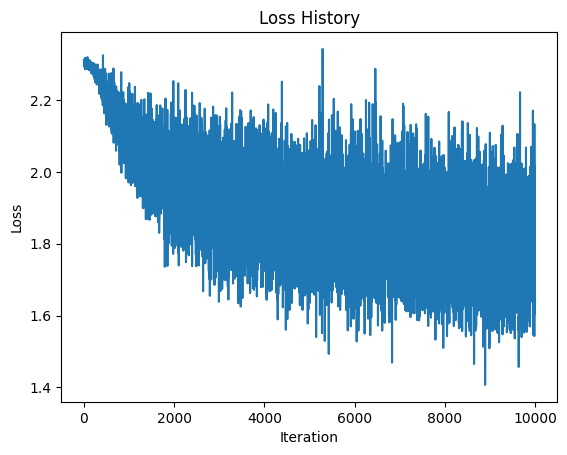

Training accuracy: 36.78%
Test accuracy: 37.16%


In [3]:
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

# 1. Data loading (same as given)
transform = transforms.Compose(
    [transforms.ToTensor(),
     transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])
batch_size = 50
trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                        download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                          shuffle=True, num_workers=2)
testset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                       download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size,
                                         shuffle=False, num_workers=2)
classes = ('plane', 'car', 'bird', 'cat',
           'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

# 2. Network parameters
Din = 3 * 32 * 32   # input size
H = 100             # middle layer nodes (new)
K = 10              # output classes
std = 1e-2          # changed from 1e-5

# Layer 1: input -> middle (new), Layer 2: middle -> output
w1 = torch.randn(Din, H) * std
b1 = torch.zeros(H)
w2 = torch.randn(H, K) * std
b2 = torch.zeros(K)

# Hyperparameters
iterations = 10     # changed from 20 (10 epochs)
lr = 1e-2           # changed from 2e-6
lr_decay = 0.9
reg = 0
loss_history = []

# 3. Training loop
for t in range(iterations):
    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        inputs, labels = data
        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)
        y_train_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        h = torch.sigmoid(x_train.mm(w1) + b1)      # middle layer + sigmoid
        scores = h.mm(w2) + b2                      # output layer
        scores = scores - scores.max(dim=1, keepdim=True)[0]  # for stability
        exp_scores = torch.exp(scores)
        probs = exp_scores / exp_scores.sum(dim=1, keepdim=True)  # softmax

        # Cross-entropy loss
        loss = -(1 / Ntr) * torch.sum(y_train_onehot * torch.log(probs + 1e-12)) \
               + reg * (torch.sum(w1 ** 2) + torch.sum(w2 ** 2))
        loss_history.append(loss.item())
        running_loss += loss.item()

        # Backpropagation (chain rule, output to input)
        dscores = (probs - y_train_onehot) / Ntr    # softmax + CE gradient
        dw2 = h.t().mm(dscores) + 2 * reg * w2
        db2 = dscores.sum(dim=0)
        dh = dscores.mm(w2.t())                     # gradient to middle layer
        dz1 = dh * h * (1 - h)                      # sigmoid derivative
        dw1 = x_train.t().mm(dz1) + 2 * reg * w1
        db1 = dz1.sum(dim=0)

        # Parameter update
        w1 -= lr * dw1
        b1 -= lr * db1
        w2 -= lr * dw2
        b2 -= lr * db2

    print(f"Epoch {t + 1}/{iterations}, Loss: {running_loss / len(trainloader):.4f}")
    lr *= lr_decay   # learning rate decay

# 4. Plot loss history
plt.plot(loss_history)
plt.title("Loss History")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()

# 5. Accuracy function
def accuracy(loader):
    correct, total = 0, 0
    with torch.no_grad():
        for inputs, labels in loader:
            x = inputs.view(inputs.shape[0], -1)
            out = torch.sigmoid(x.mm(w1) + b1).mm(w2) + b2
            pred = torch.argmax(out, dim=1)
            total += labels.size(0)
            correct += (pred == labels).sum().item()
    return 100 * correct / total

print(f"Training accuracy: {accuracy(trainloader):.2f}%")
print(f"Test accuracy: {accuracy(testloader):.2f}%")